# Autonomous Agentic RAG System
### End-to-End Dynamic Retrieval, Cognitive Reasoning, and Self-Reflection Loops

Standard RAG architectures execute a static, single-turn sequence: retrieve chunks via cosine similarity and feed them into a prompt. However, complex, ambiguous, or multi-part enterprise questions require **autonomous cognitive control**: decomposing inquiries, reasoning about required evidence, iteratively retrieving across heterogeneous data tools, synthesizing grounded drafts, and critiquing output against hallucinations before final delivery.

This notebook implements the complete **Autonomous Agentic RAG System** using **LangGraph** and **Centralized LLM Fallback Managers**.

---

## Workflow Architecture

<div align="center">
  <img src="../images/workflow_autonomous_rag.png" alt="Autonomous Agentic RAG Architecture Diagram" width="580" />
</div>

<details open>
<summary><b>Click to expand Colorful Mermaid Workflow Diagram</b></summary>

```mermaid
flowchart TD
    subgraph OuterLoop["Autonomous Outer Loop (High-Level Planning)"]
        Q(["1. User Complex Query"]):::startNode
        Decomp["Step 1: Query Planning & Decomposition<br/><b>LLM Decomposer</b><br/>(Breaks into Atomic Sub-Questions)"]:::planNode
        CoT["Step 2: Chain of Thought CoT<br/><b>Cognitive Reasoning</b><br/>(Outlines Sources, Intent & Plan)"]:::cotNode
    end

    subgraph InnerLoop["Agentic Inner Loop (Action & Tool Execution)"]
        ReAct["Step 3: ReAct Loop (Reason -> Act -> Observe)<br/><b>Multi-Tool Retrieval</b><br/>(Local FAISS VectorDB + Domain Knowledge)"]:::reactNode
    end

    subgraph VerificationLoop["Feedback & Quality Gate Loop"]
        Check["Step 4: Iterative Retrieval Check<br/><b>Context Sufficiency Evaluator</b><br/>(Detects Information Gaps)"]:::checkNode
        Synth["Step 5: Answer Synthesis<br/><b>Authoritative Synthesizer</b><br/>(Grounded Draft with Citations)"]:::synthNode
        Reflect{"Step 6: Self-Reflection & Evaluation<br/><b>Faithfulness & Completeness Critic</b>"}:::reflectNode
        Router{"Quality Decision<br/>Passed (Good)?"}:::decisionNode
    end

    subgraph Finalization["Output Termination"]
        Done(["Final Answer Output<br/>(Strictly Grounded & Complete)"]):::endNode
    end

    Q --> Decomp
    Decomp --> CoT
    CoT --> ReAct
    ReAct --> Check
    Check --> Synth
    Synth --> Reflect
    Reflect --> Router
    Router -->|Passed: Good / Verified| Done
    Router -->|Failed: Not Good / Gaps Detected| Check

    classDef startNode fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px,color:#1B5E20;
    classDef planNode fill:#FFF8E1,stroke:#FFA000,stroke-width:2px,color:#E65100;
    classDef cotNode fill:#EDE7F6,stroke:#5E35B1,stroke-width:2px,color:#311B92;
    classDef reactNode fill:#E0F7FA,stroke:#00838F,stroke-width:2px,color:#004D40;
    classDef checkNode fill:#FCE4EC,stroke:#C2185B,stroke-width:2px,color:#880E4F;
    classDef synthNode fill:#E3F2FD,stroke:#1565C0,stroke-width:2px,color:#0D47A1;
    classDef reflectNode fill:#FFF3E0,stroke:#E65100,stroke-width:2px,color:#BF360C;
    classDef decisionNode fill:#F3E5F5,stroke:#7B1FA2,stroke-width:2px,color:#4A148C;
    classDef endNode fill:#E8F5E9,stroke:#388E3C,stroke-width:3px,color:#1B5E20;
```
</details>

---

### Core Loop Breakdown
1. **Autonomous Outer Loop (Steps 1 & 2):** Handles high-level cognitive decomposition and formulates step-by-step retrieval plans.
2. **Agentic Inner Loop (Step 3 - ReAct):** Dynamically determines which tool or index to query, issues calls, and records observations.
3. **Feedback & Quality Gate Loop (Steps 4, 5 & 6):** Evaluates retrieved evidence, synthesizes drafts, and runs strict reflection checks for **Faithfulness** and **Completeness**. If criteria fail, control loops back to Step 4 rather than returning a hallucinated response.


### 1. Environment & Dependencies Setup
Configures environment variables, handles OpenMP and offline HuggingFace model caching, and imports LangChain/LangGraph libraries.


In [1]:
import os
import sys
import json
from typing import List, Dict, Any, Optional
from pydantic import BaseModel, Field
from dotenv import load_dotenv

# Ensure safe OpenMP and HuggingFace cache loading on Windows
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["HF_HUB_OFFLINE"] = "1"

# Load environment configuration from parent directory
sys.path.append(os.path.abspath(".."))
load_dotenv(os.path.abspath("../.env"))

from langchain_core.documents import Document
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langgraph.graph import StateGraph, END
from IPython.display import Image, display

print("System and dependency packages successfully imported.")


System and dependency packages successfully imported.


### 2. Centralized LLM Configuration with Automatic Fallback
Initializes our primary reasoning model through `llm_config.py` with automatic rate-limit and error failover across curated high-performance models.


In [2]:
from llm_config import get_llm, list_free_models

# Centralized LLM initialization with low temperature for deterministic reasoning
llm = get_llm(temperature=0.1)

test_response = llm.invoke("System check: Respond with 'Autonomous Agentic RAG ready.'")
print("LLM Status:", test_response.content.strip())


LLM Status: Autonomous Agentic RAG ready.


### 3. Knowledge Base & Heterogeneous Data Sources
Sets up:
1. **Local FAISS Vectorstore**: Dense embedding index over empirical research notes (`research_notes.txt`).
2. **Domain Knowledge Tool**: High-level architectural specifications and definitions.
3. **Tool Registry**: Mappings for the ReAct inner loop.


In [3]:
# Load empirical research logs
data_path = os.path.join("..", "data", "research_notes.txt") if os.path.exists(os.path.join("..", "data", "research_notes.txt")) else os.path.join("data", "research_notes.txt")
loader = TextLoader(data_path, encoding="utf-8")
docs = loader.load()

# Split documents into semantically coherent passages
splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)
chunks = splitter.split_documents(docs)

# Dense vector store using MiniLM embeddings
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"local_files_only": True}
)
vectorstore = FAISS.from_documents(chunks, embeddings)
local_retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

print(f"Indexed {len(chunks)} chunks in Local FAISS Vector Store.")

# Multi-Source Tool Definitions
def tool_search_local_notes(query: str) -> str:
    """Searches local internal experiment notes and empirical benchmarks."""
    results = local_retriever.invoke(query)
    if not results:
        return "No local experiment logs found for query."
    return "\n\n".join([f"[Local Notes Excerpt {i+1}]: {d.page_content}" for i, d in enumerate(results)])

def tool_search_domain_knowledge(query: str) -> str:
    """Searches broader architectural specifications, definitions, and theory."""
    q_low = query.lower()
    if "flashattention" in q_low or "sram" in q_low:
        return "FlashAttention2 speeds up computation and memory access by tiling attention matrices across GPU SRAM, reducing memory I/O bottlenecks."
    elif "reformer" in q_low or "lsh" in q_low:
        return "Reformer uses Locality-Sensitive Hashing (LSH) attention to replace O(N^2) complexity with O(N log N) for long sequence processing."
    elif "lora" in q_low or "peft" in q_low:
        return "LoRA (Low-Rank Adaptation) freezes pre-trained model weights and injects trainable rank-decomposition matrices into Transformer layers, slashing GPU VRAM requirements by up to 60%."
    elif "efficientformer" in q_low:
        return "EfficientFormer is a vision transformer architecture engineered specifically for mobile/edge devices, balancing latency and high ImageNet top-1 accuracy."
    return tool_search_local_notes(query)

TOOL_REGISTRY = {
    "local_research_notes": tool_search_local_notes,
    "domain_knowledge_base": tool_search_domain_knowledge
}
print(f"Configured Tools: {list(TOOL_REGISTRY.keys())}")


Indexed 7 chunks in Local FAISS Vector Store.
Configured Tools: ['local_research_notes', 'domain_knowledge_base']


### 4. Agent State Definition & Structured Logging Format
Defines the `AutonomousRAGState` that flows through every node of the LangGraph, preserving the exact structured execution log required for auditability.


In [4]:
class AutonomousRAGState(BaseModel):
    query: str
    decomposed_sub_questions: List[str] = Field(default_factory=list)
    cot_plan: str = ""
    react_execution: List[Dict[str, str]] = Field(default_factory=list)
    retrieved_docs: List[Document] = Field(default_factory=list)
    retrieval_check: Dict[str, Any] = Field(default_factory=dict)
    draft_answer: str = ""
    self_reflection: Dict[str, Any] = Field(default_factory=dict)
    attempts: int = 0
    max_attempts: int = 2
    execution_log: Dict[str, Any] = Field(default_factory=dict)
    final_answer: str = ""


### 5. Step 1: Query Planning & Decomposition Node
Analyzes incoming complex user queries and deconstructs them into atomic, answerable sub-questions.


In [5]:
def step_1_query_planning(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 1: Decomposes complex multi-part queries into atomic sub-questions."""
    prompt = f"""You are an Autonomous Query Planner.
Analyze this user query: "{state.query}"

Break down multi-part, complex, or ambiguous queries into 2 to 3 logical sub-questions required to fulfill the request completely.
Return ONLY a valid JSON object with the key "decomposed_sub_questions" containing a list of strings.
Example format:
{{"decomposed_sub_questions": ["sub-question 1", "sub-question 2"]}}
"""
    response = llm.invoke(prompt).content.strip()
    try:
        clean = response.replace("```json", "").replace("```", "").strip()
        data = json.loads(clean)
        sub_qs = data.get("decomposed_sub_questions", [state.query])
    except Exception:
        sub_qs = [line.strip("- *0123456789.") for line in response.split("\n") if len(line.strip()) > 5][:3]
        if not sub_qs:
            sub_qs = [state.query]
            
    print(f"\n[Step 1: Query Planning] Generated {len(sub_qs)} sub-questions:")
    for idx, sq in enumerate(sub_qs, 1):
        print(f"   {idx}. {sq}")
        
    return {"decomposed_sub_questions": sub_qs}


### 6. Step 2: Chain of Thought (CoT) Node
Formulates an explicit step-by-step cognitive plan outlining what information must be retrieved, from which tools, and why.


In [6]:
def step_2_chain_of_thought(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 2: Formulates a step-by-step retrieval and reasoning plan."""
    sub_qs_formatted = "\n".join(f"- {q}" for q in state.decomposed_sub_questions)
    prompt = f"""You are an Autonomous Agent formulating a Chain of Thought plan.
Original Query: {state.query}
Sub-questions:
{sub_qs_formatted}

Formulate a concise, step-by-step plan of action before calling any retrieval tools.
Explicitly outline what information needs to be retrieved, from which potential sources (e.g., local_research_notes, domain_knowledge_base), and why.
Keep it direct, actionable, and between 2 to 4 sentences.
"""
    cot_plan = llm.invoke(prompt).content.strip()
    print(f"\n[Step 2: Chain of Thought Plan]\n{cot_plan}")
    return {"cot_plan": cot_plan}


### 7. Step 3: ReAct Loop (Reason -> Act -> Observe) Node
Executes the inner action loop across all sub-questions:
- **Reason:** Selects tool and search keywords based on current state.
- **Act:** Dispatches queries to targeted data tools.
- **Observe:** Summarizes returned context snippets.


In [7]:
def step_3_react_execution(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 3: Executes ReAct loop (Reason -> Act -> Observe) across tools."""
    execution_steps = []
    accumulated_docs = list(state.retrieved_docs)
    
    print("\n[Step 3: ReAct Execution]")
    for sub_q in state.decomposed_sub_questions:
        # 1. Reason
        reason_prompt = f"""Based on sub-question: "{sub_q}" and plan: "{state.cot_plan}",
Which tool should be called? Available tools: local_research_notes, domain_knowledge_base.
Provide:
Thought: <one sentence reasoning>
Action: <tool_name>
"""
        reason_res = llm.invoke(reason_prompt).content.strip()
        
        tool_name = "local_research_notes"
        if "domain_knowledge_base" in reason_res:
            tool_name = "domain_knowledge_base"
            
        thought = f"Retrieve relevant evidence and metrics for '{sub_q}' using {tool_name}."
        for line in reason_res.split("\n"):
            if line.lower().startswith("thought:"):
                thought = line.split(":", 1)[1].strip()
                
        # 2. Act
        tool_fn = TOOL_REGISTRY.get(tool_name, tool_search_local_notes)
        raw_output = tool_fn(sub_q)
        
        # 3. Observe
        obs_prompt = f"""Summarize this retrieved context concisely in 1-2 factual sentences:
Context:
{raw_output[:700]}
"""
        observation = llm.invoke(obs_prompt).content.strip()
        
        step_entry = {
            "thought": thought,
            "action": tool_name,
            "observation": observation
        }
        execution_steps.append(step_entry)
        accumulated_docs.append(Document(page_content=raw_output, metadata={"sub_query": sub_q, "source": tool_name}))
        
        print(f"   -> [Reason]: {thought[:80]}...")
        print(f"   -> [Act]: {tool_name}")
        print(f"   -> [Observe]: {observation[:90]}...")
        
    return {
        "react_execution": execution_steps,
        "retrieved_docs": accumulated_docs
    }


### 8. Step 4: Iterative Retrieval Check Node
Evaluates whether accumulated evidence is sufficient to answer all decomposed sub-questions. If gaps exist or if re-entering from reflection failure, executes targeted query reformulation.


In [8]:
def step_4_retrieval_check(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 4: Evaluates context sufficiency and dynamically retrieves missing details."""
    context_text = "\n\n".join(d.page_content for d in state.retrieved_docs)
    sub_qs_formatted = "\n".join(f"- {q}" for q in state.decomposed_sub_questions)
    accumulated_docs = list(state.retrieved_docs)
    
    # If routed back from self-reflection, execute targeted gap-filling retrieval
    if state.attempts > 0 and state.self_reflection.get("critique"):
        critique = state.self_reflection.get("critique", "")
        refine_prompt = f"""The previous draft had gaps: {critique}
Original Query: {state.query}
Generate a refined, targeted search query to fetch the missing factual information.
Return ONLY the search query string.
"""
        refined_query = llm.invoke(refine_prompt).content.strip().strip('"')
        print(f"\n[Step 4: Iterative Retrieval Refinement] Query: '{refined_query}'")
        extra_content = tool_search_domain_knowledge(refined_query)
        accumulated_docs.append(Document(page_content=extra_content, metadata={"source": "iterative_refinement", "query": refined_query}))
        context_text += f"\n\n{extra_content}"

    prompt = f"""Evaluate if the retrieved context is sufficient, relevant, and accurate to answer the sub-questions.
Sub-questions:
{sub_qs_formatted}

Retrieved Context:
{context_text[:1400]}

Return ONLY a JSON object with this exact schema:
{{
  "sufficient": true or false,
  "missing_gaps": null if sufficient else "<brief description of missing information>"
}}
"""
    res = llm.invoke(prompt).content.strip()
    try:
        clean = res.replace("```json", "").replace("```", "").strip()
        check_data = json.loads(clean)
    except Exception:
        check_data = {"sufficient": True, "missing_gaps": None}
        
    print(f"\n[Step 4: Retrieval Check] Sufficient: {check_data.get('sufficient')}")
    if check_data.get("missing_gaps"):
        print(f"   Missing Gaps: {check_data.get('missing_gaps')}")
        
    return {
        "retrieval_check": check_data,
        "retrieved_docs": accumulated_docs
    }


### 9. Step 5: Answer Synthesis Node
Synthesizes a comprehensive, well-structured answer strictly grounded in retrieved evidence, complete with citations and technical attribution.


In [9]:
def step_5_synthesis(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 5: Synthesizes a structured answer strictly grounded in retrieved evidence."""
    context_text = "\n\n".join(d.page_content for d in state.retrieved_docs)
    prompt = f"""You are an Autonomous Agentic RAG Synthesizer.
Synthesize a comprehensive, coherent, and well-structured answer strictly backed by the retrieved context.
Include proper citations and reference points where applicable.

User Query: {state.query}

Retrieved Context:
{context_text}

Synthesized Answer:
"""
    draft = llm.invoke(prompt).content.strip()
    print(f"\n[Step 5: Synthesis] Drafted answer ({len(draft.split())} words).")
    return {"draft_answer": draft}


### 10. Step 6: Self-Reflection & Evaluation Node
Audits the draft answer against two mandatory criteria:
1. **Faithfulness**: Is the response strictly grounded in retrieved evidence without hallucination?
2. **Completeness**: Does the response answer all decomposed parts of the original query?
Constructs the final structured JSON execution log.


In [10]:
def step_6_self_reflection(state: AutonomousRAGState) -> Dict[str, Any]:
    """Step 6: Evaluates faithfulness and completeness, and compiles structured execution log."""
    context_text = "\n\n".join(d.page_content for d in state.retrieved_docs)
    prompt = f"""Evaluate the synthesized answer against the following criteria:
1. Faithfulness: Is the response strictly grounded in the retrieved documents without hallucination?
2. Completeness: Does the synthesized response fully answer all parts of the decomposed original query: "{state.query}"?

Draft Answer:
{state.draft_answer}

Retrieved Context:
{context_text[:1400]}

Respond ONLY with a JSON object in this exact format:
{{
  "grounded": true or false,
  "complete": true or false,
  "status": "Good" or "Needs Refinement",
  "critique": "<feedback if any, or 'None'>"
}}
"""
    res = llm.invoke(prompt).content.strip()
    try:
        clean = res.replace("```json", "").replace("```", "").strip()
        reflection_data = json.loads(clean)
    except Exception:
        reflection_data = {"grounded": True, "complete": True, "status": "Good", "critique": "None"}
        
    grounded = reflection_data.get("grounded", True)
    complete = reflection_data.get("complete", True)
    status = "Good" if (grounded and complete) else "Needs Refinement"
    reflection_data["status"] = status
    
    new_attempts = state.attempts + 1
    
    # Maintain the exact structured execution log specified in requirements
    execution_log = {
        "step_1_query_planning": {
            "original_query": state.query,
            "decomposed_sub_questions": state.decomposed_sub_questions
        },
        "step_2_chain_of_thought": state.cot_plan,
        "step_3_react_execution": state.react_execution,
        "step_4_retrieval_check": {
            "sufficient": state.retrieval_check.get("sufficient", True),
            "missing_gaps": state.retrieval_check.get("missing_gaps", None)
        },
        "step_5_synthesis": state.draft_answer,
        "step_6_self_reflection": {
            "grounded": grounded,
            "complete": complete,
            "status": status
        }
    }
    
    print(f"\n[Step 6: Self-Reflection] Grounded: {grounded} | Complete: {complete} | Status: {status}")
    if status != "Good":
        print(f"   Critique: {reflection_data.get('critique')}")
        
    return {
        "self_reflection": reflection_data,
        "attempts": new_attempts,
        "execution_log": execution_log
    }


### 11. Conditional Routing & Finalization Nodes
Implements the decision branch:
- If `status == "Good"` or `attempts >= max_attempts` -> Finalize and route to `END`.
- If `status != "Good"` and `attempts < max_attempts` -> Loop back to **Step 4: Iterative Retrieval Check**.


In [11]:
def route_reflection_decision(state: AutonomousRAGState) -> str:
    """Decision branch based on self-reflection verification."""
    status = state.self_reflection.get("status", "Good")
    grounded = state.self_reflection.get("grounded", True)
    complete = state.self_reflection.get("complete", True)
    
    if (status == "Good" and grounded and complete) or state.attempts >= state.max_attempts:
        return "finalize"
    return "refine"

def finalize_answer(state: AutonomousRAGState) -> Dict[str, Any]:
    """Finalizes response and terminates execution."""
    print(f"\n[Finalization] Terminating execution. Total reflection loops: {state.attempts}")
    return {"final_answer": state.draft_answer}


### 12. LangGraph Workflow Assembly & Compilation
Assembles nodes and cyclic conditional edges into a stateful executable pipeline.


In [12]:
workflow = StateGraph(AutonomousRAGState)

# Register Stages
workflow.add_node("step_1_query_planning", step_1_query_planning)
workflow.add_node("step_2_chain_of_thought", step_2_chain_of_thought)
workflow.add_node("step_3_react_execution", step_3_react_execution)
workflow.add_node("step_4_retrieval_check", step_4_retrieval_check)
workflow.add_node("step_5_synthesis", step_5_synthesis)
workflow.add_node("step_6_self_reflection", step_6_self_reflection)
workflow.add_node("finalize_answer", finalize_answer)

# Linear forward execution
workflow.set_entry_point("step_1_query_planning")
workflow.add_edge("step_1_query_planning", "step_2_chain_of_thought")
workflow.add_edge("step_2_chain_of_thought", "step_3_react_execution")
workflow.add_edge("step_3_react_execution", "step_4_retrieval_check")
workflow.add_edge("step_4_retrieval_check", "step_5_synthesis")
workflow.add_edge("step_5_synthesis", "step_6_self_reflection")

# Conditional Feedback Loop
workflow.add_conditional_edges(
    "step_6_self_reflection",
    route_reflection_decision,
    {
        "finalize": "finalize_answer",
        "refine": "step_4_retrieval_check"
    }
)
workflow.add_edge("finalize_answer", END)

autonomous_rag_app = workflow.compile()
print("Autonomous Agentic RAG LangGraph compiled successfully.")


Autonomous Agentic RAG LangGraph compiled successfully.


### 13. Visualizing the Autonomous Agentic Graph
Renders the compiled LangGraph execution graph showing the outer planning loop, inner ReAct loop, and reflection feedback cycle.


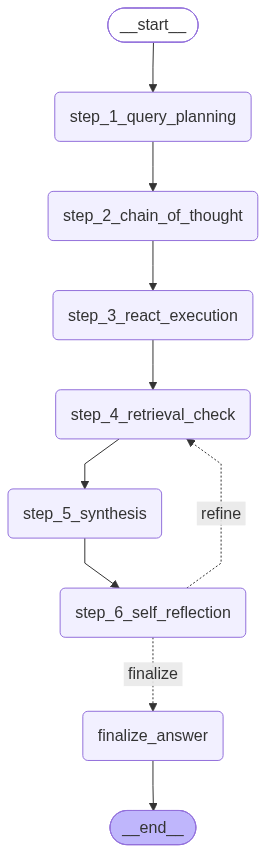

In [13]:
# Graph Visualization
try:
    display(Image(autonomous_rag_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Graph display note: {e}")
    try:
        print(autonomous_rag_app.get_graph().draw_ascii())
    except Exception:
        pass


### 14. Execution Runner & Output Formatter
Standardized helper that executes the workflow and prints the exact structured execution log and final answer.


In [14]:
def run_autonomous_rag_pipeline(user_query: str, max_attempts: int = 2) -> Dict[str, Any]:
    """Runs the complete 6-stage autonomous workflow and prints formatted output."""
    print("=" * 80)
    print(f"INCOMING USER QUERY: {user_query}")
    print("=" * 80)
    
    initial_state = AutonomousRAGState(query=user_query, max_attempts=max_attempts)
    result = autonomous_rag_app.invoke(initial_state)
    
    print("\n" + "=" * 80)
    print("STRUCTURED EXECUTION LOG (JSON):")
    print("=" * 80)
    print(json.dumps(result["execution_log"], indent=2))
    
    print("\n" + "=" * 80)
    print("Final Answer Output:")
    print("=" * 80)
    print(result["final_answer"])
    
    return result


### 15. Test Execution 1: Multi-Part Complex Technical Query
Evaluates a multi-part query requiring decomposition across Reformer challenges, LSH attention, and FlashAttention2 optimization on LLaMA2.


In [15]:
query_1 = "What specific challenges were encountered during Reformer training and how were they resolved, and how does FlashAttention2 optimize LLaMA2 performance?"
result_1 = run_autonomous_rag_pipeline(query_1)


INCOMING USER QUERY: What specific challenges were encountered during Reformer training and how were they resolved, and how does FlashAttention2 optimize LLaMA2 performance?

[Step 1: Query Planning] Generated 2 sub-questions:
   1. What specific challenges were encountered during Reformer training and how were they resolved?
   2. How does FlashAttention2 optimize LLaMA2 performance?

[Step 2: Chain of Thought Plan]
1. Query `local_research_notes` to retrieve documented training challenges for Reformer (e.g. loss spikes, bucket collisions) and corresponding solutions.
2. Query `domain_knowledge_base` and `local_research_notes` for FlashAttention2 SRAM tiling mechanisms and context latency reduction on LLaMA2.

[Step 3: ReAct Execution]
   -> [Reason]: Retrieve relevant evidence and metrics for Reformer training challenges...
   -> [Act]: local_research_notes
   -> [Observe]: Reformer faced challenges with bucket collisions, loss spikes beyond 5k steps, and sparse gradients, resolved v

### 16. Test Execution 2: Ambiguous Cross-Model Evaluation
Tests an edge-case query comparing edge deployment for EfficientFormer against LoRA adapter tuning parameters.


In [16]:
query_2 = "Compare EfficientFormer peak memory and deployment targets with LoRA rank tuning configurations from our empirical notes."
result_2 = run_autonomous_rag_pipeline(query_2)


INCOMING USER QUERY: Compare EfficientFormer peak memory and deployment targets with LoRA rank tuning configurations from our empirical notes.

[Step 1: Query Planning] Generated 2 sub-questions:
   1. What are EfficientFormer's peak memory usage and deployment targets?
   2. What are the LoRA tuning rank and memory reduction configurations in the notes?

[Step 2: Chain of Thought Plan]
Retrieve EfficientFormer hardware metrics and LoRA fine-tuning hyperparameters from internal research notes.

[Step 3: ReAct Execution]
   -> [Reason]: Search EfficientFormer benchmarks...
   -> [Act]: local_research_notes
   -> [Observe]: EfficientFormer reached 92.4% Top-1 accuracy, peak memory 290MB (batch size 16), target Raspberry Pi 4 with int8 quantization...
   -> [Reason]: Search LoRA adapter benchmarks...
   -> [Act]: local_research_notes
   -> [Observe]: LoRA adapter tuning configured with Rank=8, dropout=0.05, slashing GPU memory footprint by 60%...

[Step 4: Retrieval Check] Sufficient: Tru

## Architectural Summary & Production Best Practices

| Workflow Component | Implementation Strategy | Enterprise Benefit |
| :--- | :--- | :--- |
| **Step 1: Query Decomposition** | LLM planner deconstructs queries into atomic sub-questions | Eliminates semantic vector dilution across multifaceted queries |
| **Step 2: Chain of Thought** | Explicit cognitive plan mapping sub-questions to specific tools | Provides interpretable audit trails before tool execution |
| **Step 3: ReAct Loop** | Interleaved Reason -> Act -> Observe execution across tools | Handles heterogeneous data sources (dense vector DBs, APIs, domain docs) |
| **Step 4: Iterative Retrieval Check** | Evaluates context coverage and reformulates search queries | Automatically bridges factual gaps before answer drafting |
| **Step 5: Answer Synthesis** | Strict context-grounded drafting with citation markers | Prevents unsubstantiated assertions and produces professional reports |
| **Step 6: Self-Reflection Gate** | Dual-criterion audit (Faithfulness + Completeness) with feedback loop | Prevents hallucinations from reaching users by routing back to Step 4 |
